# Линейная регрессия в scikit-learn — с нуля

**Ноутбук 1 из серии «sklearn с нуля».** Следующий — логистическая регрессия.

## Как с этим работать

- Читай сверху вниз, ячейки запускай по порядку (`Shift + Enter`). Ячейки зависят друг от друга: переменные из одних используются в других.
- Не просто читай, а **меняй числа и смотри, что произойдёт**. Это лучший способ понять модель.
- В конце — 6 упражнений. Сначала попробуй решить сам, **решения лежат в самом низу** ноутбука.

## Что ты узнаешь

1. Что такое регрессия, признаки, целевая переменная, обучение и предсказание.
2. Как устроена линейная модель и что значит «подобрать прямую по точкам».
3. Что такое функция потерь, и как модель обучается (градиентный спуск и точная формула) — **своими руками на numpy**.
4. Как всё это делается в sklearn одной строкой и что при этом происходит внутри.
5. Метрики качества: MAE, MSE, RMSE, R² — формулы и смысл.
6. Train/test, переобучение, регуляризация (Ridge, Lasso), кросс-валидация.
7. Подводные камни: масштаб признаков, выбросы, мультиколлинеарность.

**Что нужно знать заранее:** основы Python, numpy, pandas и matplotlib. Школьная алгебра: формула прямой, сумма, среднее. Производные пригодятся только в одном месте, и там я всё объясню.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             root_mean_squared_error, r2_score)

plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 11})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

print("Всё импортировано, можно работать!")

Всё импортировано, можно работать!

---
## 1. Что такое машинное обучение и что такое регрессия

В обычной программе **правила пишет человек**: «если площадь больше 50 м², то цена такая-то». В машинном обучении мы поступаем иначе: показываем компьютеру много **примеров** (вход → правильный ответ), а он **сам подбирает правила**.

### Словарь, без которого дальше никак

| Термин | Что это | Пример (предсказываем цену квартиры) |
|---|---|---|
| **Объект** (наблюдение) | одна строка таблицы | одна конкретная квартира |
| **Признаки** (features), обозначаем $X$ | столбцы, по которым предсказываем | площадь, этаж, район |
| **Целевая переменная** (target), обозначаем $y$ | то, что хотим предсказать | цена |
| **Модель** | формула с настраиваемыми числами | «цена = 0.1 · площадь + 0.5» |
| **Параметры модели** | те самые настраиваемые числа | 0.1 и 0.5 |
| **Обучение** (`fit`) | подбор параметров по данным | найти 0.1 и 0.5 |
| **Предсказание** (`predict`) | подстановка новых данных в формулу | площадь 60 → цена 6.5 |

### Два главных типа задач «с учителем»

- **Регрессия** — $y$ это **число** (цена, температура, зарплата, время доставки). Этот ноутбук.
- **Классификация** — $y$ это **категория** (спам / не спам, болезнь / здоров). Следующий ноутбук.

### Линейная регрессия

Самая простая и при этом самая важная модель. Идея: **ответ — это взвешенная сумма признаков**. Например:

$$\text{цена} = w_1 \cdot \text{площадь} + w_2 \cdot \text{этаж} + b$$

Числа $w_1, w_2$ называются **весами** (коэффициентами), $b$ — **свободным членом** (intercept, смещение). Обучение — это поиск таких $w$ и $b$, чтобы предсказания были как можно ближе к реальным ответам.

Почему начинать стоит с неё: она быстро обучается, легко интерпретируется (вес показывает «вклад» признака), служит хорошим базовым вариантом (baseline), а почти всё из этого ноутбука (метрики, train/test, регуляризация, кросс-валидация) работает и для остальных моделей.

---
## 2. Один признак: прямая по точкам

Начнём с простейшего случая: **один признак**. Сгенерируем условные данные: площадь квартиры (м²) и цена (млн ₽). Данные искусственные, поэтому мы знаем «истину»: цена $= 0.5 + 0.1 \cdot \text{площадь} +$ случайный шум. Модель этой истины, конечно, не знает и должна восстановить её по точкам.

In [ ]:
rng = np.random.default_rng(42)          # генератор случайных чисел с фиксированным seed (результат воспроизводим)
n = 60
area = rng.uniform(25, 120, n)           # площадь, м²
price = 0.5 + 0.1 * area + rng.normal(0, 1.0, n)   # цена, млн ₽ = истина + шум

df = pd.DataFrame({"area": area.round(1), "price": price.round(2)})
df.head()

,area,price
0,98.5,9.49
1,66.7,8.14
2,106.6,9.47
3,91.2,9.29
4,33.9,4.06


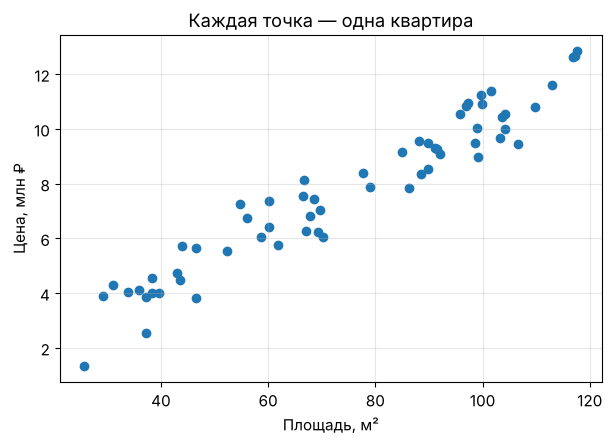

In [ ]:
plt.scatter(df["area"], df["price"])
plt.xlabel("Площадь, м²")
plt.ylabel("Цена, млн ₽")
plt.title("Каждая точка — одна квартира")
plt.show()

Видно, что точки лежат примерно вдоль прямой: чем больше площадь, тем выше цена. Но не точно по прямой — есть шум (разброс из-за этажа, района, ремонта и всего, чего у нас нет в данных).

### Модель

$$\hat{y} = w \cdot x + b$$

- $x$ — признак (площадь),
- $\hat{y}$ («игрек с крышкой») — **предсказание** модели; настоящий ответ обозначаем $y$ без крышки,
- $w$ — **наклон** прямой (на сколько растёт цена при росте площади на 1 м²),
- $b$ — **сдвиг** (значение при $x = 0$).

Разных прямых бесконечно много. Какая из них «лучшая»? Нужна **мера плохости** прямой.

### Остатки и функция потерь

Для каждого объекта $i$ **ошибка** (остаток, residual) — это $e_i = y_i - \hat{y}_i$: настоящее минус предсказанное.

Чтобы свести ошибки всех объектов в одно число, берём **среднюю квадратичную ошибку** (MSE, mean squared error):

$$\text{MSE}(w, b) = \frac{1}{n}\sum_{i=1}^{n}\bigl(y_i - \hat{y}_i\bigr)^2 = \frac{1}{n}\sum_{i=1}^{n}\bigl(y_i - w x_i - b\bigr)^2$$

Зачем **квадрат**?
1. Ошибки разных знаков не гасят друг друга (+5 и −5 в сумме дали бы 0, хотя модель ошибается).
2. Большие ошибки штрафуются сильнее маленьких (ошибка 10 даёт штраф 100, а десять ошибок по 1 — всего 10).
3. Функция гладкая, у неё удобные производные (это пригодится ниже).

Такая функция, которую мы минимизируем при обучении, называется **функцией потерь** (loss function). Обучение = поиск $w, b$ с минимальным значением потерь.

### Посчитаем руками на трёх точках

Три квартиры: площади 30, 50, 70 м², цены 3, 5, 6 млн. Возьмём прямую с $w = 0.08$, $b = 0.5$:

| $x$ | $y$ | $\hat y = 0.08x + 0.5$ | $e = y - \hat y$ | $e^2$ |
|---|---|---|---|---|
| 30 | 3 | 2.9 | 0.1 | 0.01 |
| 50 | 5 | 4.5 | 0.5 | 0.25 |
| 70 | 6 | 6.1 | −0.1 | 0.01 |

$\text{MSE} = (0.01 + 0.25 + 0.01) / 3 = 0.09$. Проверим кодом:

предсказания: [2.9 4.5 6.1]
остатки:      [ 0.1  0.5 -0.1]
MSE = 0.09

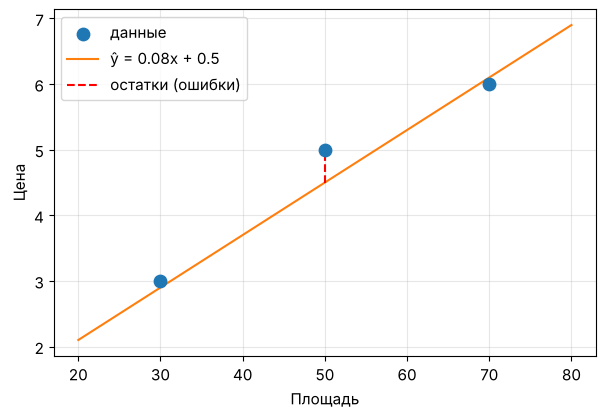

In [ ]:
x3 = np.array([30, 50, 70])
y3 = np.array([3, 5, 6])
w, b = 0.08, 0.5

y_hat = w * x3 + b          # предсказания (numpy применяет формулу сразу ко всем элементам)
errors = y3 - y_hat         # остатки
mse = np.mean(errors ** 2)

print("предсказания:", y_hat)
print("остатки:     ", errors)
print("MSE =", round(mse, 4))

plt.scatter(x3, y3, s=80, label="данные", zorder=3)
xs = np.linspace(20, 80, 10)
plt.plot(xs, w * xs + b, color="C1", label=f"ŷ = {w}x + {b}")
plt.vlines(x3, y_hat, y3, color="red", linestyles="--", label="остатки (ошибки)")
plt.legend(); plt.xlabel("Площадь"); plt.ylabel("Цена")
plt.show()

Красные отрезки — это ошибки. MSE — среднее из их **квадратов**. Лучшая прямая — та, у которой эти отрезки в сумме (по квадратам) самые короткие.

> **Попробуй сам.** Поменяй `w` и `b` в ячейке выше (например, `w = 0.075`, `b = 0.92`) и посмотри, как изменится MSE. Ниже мы увидим, что эти значения как раз почти оптимальны.

---
## 3. Как найти лучшие $w$ и $b$

Есть три способа. Первые два мы сделаем сами, чтобы понять, что происходит «под капотом» sklearn.

### 3.1. Функция потерь как ландшафт

Зафиксируем $b = 0.5$ и посмотрим, как MSE на наших 60 квартирах зависит от $w$:

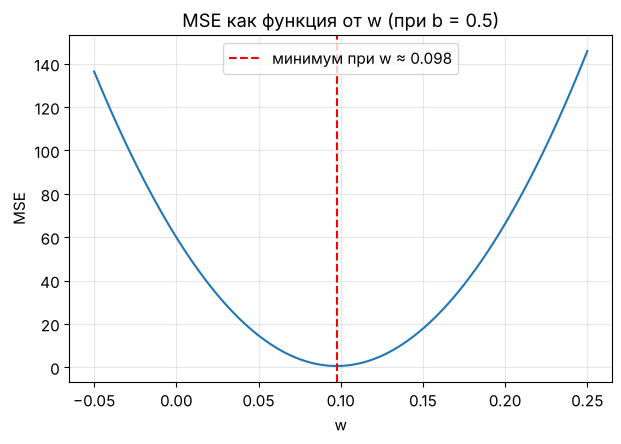

In [ ]:
ws = np.linspace(-0.05, 0.25, 200)
losses = [np.mean((w_ * area + 0.5 - price) ** 2) for w_ in ws]

plt.plot(ws, losses)
best_w = ws[np.argmin(losses)]
plt.axvline(best_w, color="red", linestyle="--", label=f"минимум при w ≈ {best_w:.3f}")
plt.xlabel("w"); plt.ylabel("MSE"); plt.legend()
plt.title("MSE как функция от w (при b = 0.5)")
plt.show()

Получилась **парабола** с одним чётко выраженным минимумом. Это не случайность: для линейной регрессии MSE всегда «чашка» (выпуклая функция), поэтому у неё **один** минимум и нет ловушек в виде локальных минимумов. Для двух параметров $(w, b)$ это трёхмерная чаша, и нужно найти её дно.

### 3.2. Градиентный спуск

Представь, что ты стоишь на склоне чаши в тумане и хочешь спуститься вниз. Ты не видишь дна, но чувствуешь, куда склон идёт вниз под ногами. Значит, нужно делать шаги **в сторону наибольшего спуска**, и так до самого дна.

Математически «куда склон идёт вверх» показывает **градиент** — вектор производных по параметрам. Для MSE:

$$\frac{\partial\,\text{MSE}}{\partial w} = \frac{2}{n}\sum_i (\hat y_i - y_i)\,x_i, \qquad \frac{\partial\,\text{MSE}}{\partial b} = \frac{2}{n}\sum_i (\hat y_i - y_i)$$

Шаг алгоритма (идём **против** градиента):

$$w \leftarrow w - \eta \cdot \frac{\partial\,\text{MSE}}{\partial w}, \qquad b \leftarrow b - \eta \cdot \frac{\partial\,\text{MSE}}{\partial b}$$

где $\eta$ («эта») — **скорость обучения** (learning rate): размер шага. Слишком маленький — спускаемся вечность; слишком большой — перепрыгиваем дно и улетаем.

Чтобы спуск был стабильным, признак обычно **стандартизируют**: $x_{std} = (x - \bar x)/\sigma_x$ (среднее 0, разброс 1). Сделаем это и обучим модель вручную:

после 100 шагов: w = 2.6572, b = 7.7311, MSE = 0.5592

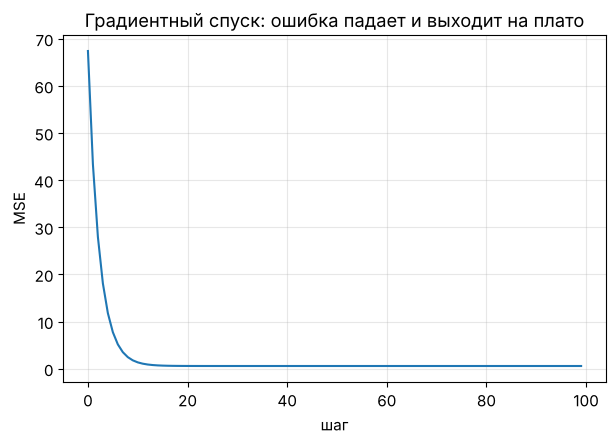

In [ ]:
x_std = (area - area.mean()) / area.std()

w, b = 0.0, 0.0        # начинаем с нулей
lr = 0.1               # скорость обучения η
history = []

for step in range(100):
    y_hat = w * x_std + b
    err = y_hat - price                      # (ŷ - y)
    history.append(np.mean(err ** 2))        # запоминаем MSE, чтобы нарисовать график
    dw = 2 * np.mean(err * x_std)            # производная по w
    db = 2 * np.mean(err)                    # производная по b
    w -= lr * dw                             # шаг против градиента
    b -= lr * db

print(f"после 100 шагов: w = {w:.4f}, b = {b:.4f}, MSE = {history[-1]:.4f}")

plt.plot(history)
plt.xlabel("шаг"); plt.ylabel("MSE"); plt.title("Градиентный спуск: ошибка падает и выходит на плато")
plt.show()

Ошибка быстро падает и перестаёт меняться, то есть мы «доехали до дна». Сравним с готовой моделью sklearn **на тех же стандартизированных данных**:

In [ ]:
sk = LinearRegression().fit(x_std.reshape(-1, 1), price)
print(f"наш градиентный спуск: w = {w:.6f}, b = {b:.6f}")
print(f"sklearn:               w = {sk.coef_[0]:.6f}, b = {sk.intercept_:.6f}")

наш градиентный спуск: w = 2.657230, b = 7.731100
sklearn:               w = 2.657230, b = 7.731100

Совпало до 5–6 знаков. То есть `LinearRegression` внутри делает то же самое по смыслу (точнее, находит минимум сразу, без шагов — см. ниже).

**Как вернуться к исходным единицам.** Мы обучали модель на $x_{std}$, а не на площади в м². Подставим $x_{std} = (x-\bar x)/\sigma$ в $\hat y = w\,x_{std} + b$:

$$\hat y = \frac{w}{\sigma}\,x + \Bigl(b - \frac{w\,\bar x}{\sigma}\Bigr)$$

То есть наклон для «сырой» площади — $w/\sigma$, а свободный член — $b - w\bar x/\sigma$:

In [ ]:
w_raw = w / area.std()
b_raw = b - w * area.mean() / area.std()
print(f"в исходных единицах: цена ≈ {w_raw:.4f} * площадь + {b_raw:.4f}")
print("(истина, по которой генерировали данные: 0.1 * площадь + 0.5, остальное — шум)")

в исходных единицах: цена ≈ 0.0995 * площадь + 0.3337
(истина, по которой генерировали данные: 0.1 * площадь + 0.5, остальное — шум)

### 3.3. Точная формула (аналитическое решение)

Для линейной регрессии минимум MSE можно найти **без итераций**: приравнять производные к нулю и решить уравнения. Для одного признака получается:

$$w = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2} = \frac{\operatorname{cov}(x, y)}{\operatorname{var}(x)}, \qquad b = \bar y - w\,\bar x$$

Смысл: наклон — это отношение «насколько $x$ и $y$ меняются вместе» к «насколько $x$ меняется сам по себе». А $b$ подбирается так, чтобы прямая проходила через точку средних $(\bar x, \bar y)$.

Проверим на трёх точках из раздела 2: $\bar x = 50$, $\bar y = 14/3 \approx 4.667$, числитель $= 60$, знаменатель $= 800$, значит $w = 0.075$, $b = 4.667 - 0.075 \cdot 50 \approx 0.917$ (те самые «почти оптимальные» значения из подсказки выше). А теперь для всех 60 квартир:

In [ ]:
w_an = np.sum((area - area.mean()) * (price - price.mean())) / np.sum((area - area.mean()) ** 2)
b_an = price.mean() - w_an * area.mean()
print(f"аналитически: w = {w_an:.4f}, b = {b_an:.4f}")

аналитически: w = 0.0995, b = 0.3337

Те же $w$ и $b$, что получил градиентный спуск, пересчитанный в исходные единицы. Три пути, один результат.

Для **многих признаков** аналитическое решение записывают в матричном виде. Если $X$ — матрица признаков (с добавленным столбцом из единиц для $b$), а $w$ — вектор всех параметров:

$$w = (X^\top X)^{-1} X^\top y \qquad \text{(нормальное уравнение)}$$

Это одна из задач в конце. На практике sklearn решает её через более устойчивые численные методы (SVD / `lstsq`), а не через явное обращение матрицы.

**Когда что использовать:** для линейной регрессии на разумных объёмах данных — точное решение (так и делает `LinearRegression`). Градиентный спуск нужен, когда данных очень много, или для моделей, у которых точной формулы нет (логистическая регрессия, нейросети — следующие ноутбуки).

---
## 4. Теперь то же самое в sklearn

### Единый интерфейс sklearn

У всех моделей и преобразователей в sklearn одинаковый набор методов. Выучить один раз — пользоваться везде:

| Метод | Что делает | У кого есть |
|---|---|---|
| `.fit(X, y)` | **обучает** (подбирает параметры по данным) | модели и преобразователи |
| `.predict(X)` | **предсказывает** $y$ для новых $X$ | модели |
| `.score(X, y)` | считает «оценку» качества (для регрессии — $R^2$) | модели |
| `.transform(X)` | преобразует данные (например, масштабирует) | преобразователи (`StandardScaler`, …) |

Параметры модели, **найденные при обучении**, лежат в атрибутах с подчёркиванием на конце: `coef_`, `intercept_`. Подчёркивание — это договорённость: «это появилось после `fit`».

### Важно: форма данных

`X` в sklearn — всегда **двумерная** таблица «объекты × признаки», даже если признак один. `y` — одномерный. Посмотрим, что будет, если забыть:

In [ ]:
try:
    LinearRegression().fit(df["area"], df["price"])      # X одномерный — ошибка!
except ValueError as e:
    print("Ошибка:", str(e)[:200], "...")

Ошибка: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead. ...

In [ ]:
X = df[["area"]]       # двойные скобки → DataFrame (2D). Для numpy: area.reshape(-1, 1)
y = df["price"]        # одинарные → Series (1D)
print("форма X:", X.shape, "| форма y:", y.shape)

model = LinearRegression()   # 1. создаём модель
model.fit(X, y)              # 2. обучаем
print(f"w (coef_)      = {model.coef_[0]:.4f}")
print(f"b (intercept_) = {model.intercept_:.4f}")

форма X: (60, 1) | форма y: (60,)
w (coef_)      = 0.0994
b (intercept_) = 0.3333

Совпало с нашими формулами из раздела 3.3 (`w_an`, `b_an`). Теперь предсказания для новых квартир и график:

   area  предсказанная цена
0    45                4.81
1    80                8.29
2   110               11.27

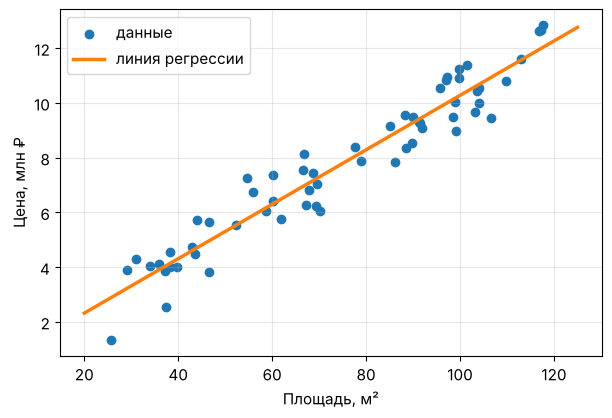

In [ ]:
new = pd.DataFrame({"area": [45, 80, 110]})
print(pd.DataFrame({"area": new["area"], "предсказанная цена": model.predict(new).round(2)}))

grid = pd.DataFrame({"area": np.linspace(20, 125, 50)})
plt.scatter(df["area"], df["price"], label="данные")
plt.plot(grid["area"], model.predict(grid), color="C1", linewidth=2.5, label="линия регрессии")
plt.xlabel("Площадь, м²"); plt.ylabel("Цена, млн ₽"); plt.legend()
plt.show()

**Как читать результат:** `coef_ ≈ 0.1` означает «каждый дополнительный квадратный метр в среднем добавляет примерно 0.1 млн ₽ к цене». Это и есть главная ценность линейной модели: её коэффициенты можно прочитать человеческим языком.

---
## 5. Много признаков и честная проверка на тестовой выборке

С одним признаком всё нарисовать легко, но реальные задачи многомерные. Формула та же, просто слагаемых больше:

$$\hat y = w_1 x_1 + w_2 x_2 + \dots + w_p x_p + b = \sum_{j=1}^{p} w_j x_j + b$$

В векторном виде: $\hat y = x^\top w + b$. Геометрически: при двух признаках модель — это **плоскость**, при трёх и больше — «гиперплоскость» (нарисовать нельзя, но алгебра работает так же).

### Данные: diabetes

Встроенный датасет sklearn: 442 пациента, 10 признаков (возраст, пол, индекс массы тела `bmi`, давление `bp`, шесть показателей крови `s1`–`s6`). Целевая переменная — **числовая оценка прогрессирования болезни через год**. Загрузим как таблицу:

In [ ]:
data = load_diabetes(as_frame=True)
X = data.data              # признаки (DataFrame)
y = data.target            # целевая переменная (Series)

print("размер X:", X.shape)
X.head()

размер X: (442, 10)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466


In [ ]:
X.describe().loc[["mean", "std", "min", "max"]]

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
mean,-2.5118e-19,1.2308e-17,-2.2456e-16,-4.7976e-17,-1.3815e-17,3.9184e-17,-5.7772e-18,-9.0425e-18,9.2686e-17,1.1303e-17
std,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02,4.7619e-02
min,-1.0723e-01,-4.4642e-02,-9.0275e-02,-1.1240e-01,-1.2678e-01,-1.1561e-01,-1.0231e-01,-7.6395e-02,-1.2610e-01,-1.3777e-01
max,1.1073e-01,5.0680e-02,1.7056e-01,1.3204e-01,1.5391e-01,1.9879e-01,1.8118e-01,1.8523e-01,1.3360e-01,1.3561e-01


Обрати внимание: среднее каждого признака ≈ 0, а разброс одинаковый (~0.05). Авторы датасета **уже отмасштабировали** признаки, поэтому здесь они выглядят «странно» (пол или возраст — не в годах). Это упрощает нам жизнь; на своих данных масштабирование придётся делать самому (раздел 7).

### Зачем делить данные на train и test

Если обучить модель на всех данных и тут же проверить на них же, то мы проверяем, как хорошо она **запомнила** ответы, а не как **обобщает**. Это как принять экзамен по билетам, которые студент уже видел. Правильно:

1. Делим данные на две части: **train** (на ней учимся) и **test** (откладываем и не трогаем до самой оценки).
2. Обучаем на train.
3. Оцениваем на test: это честная имитация «новых, ранее не виденных» данных.

Для этого есть `train_test_split`. Параметр `random_state` фиксирует случайность, чтобы результат повторялся.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print("train:", X_train.shape, "| test:", X_test.shape)

model = LinearRegression()
model.fit(X_train, y_train)        # учимся ТОЛЬКО на train
y_pred = model.predict(X_test)     # предсказываем для test

pd.DataFrame({"реальное": y_test.values[:6], "предсказанное": y_pred[:6].round(1)})

train: (331, 10) | test: (111, 10)

,реальное,предсказанное
0,219.0,137.9
1,70.0,182.5
2,202.0,129.9
3,230.0,292.6
4,111.0,124.9
5,84.0,89.7


---
## 6. Метрики: как измерить качество

Глазами сравнивать предсказания неудобно, нужны числа. Основные метрики регрессии ($n$ — число объектов в тесте):

| Метрика | Формула | Смысл |
|---|---|---|
| **MAE** | $\frac1n\sum \lvert y_i-\hat y_i\rvert$ | средняя ошибка в единицах $y$. Легко объяснить: «в среднем ошибаемся на 40 пунктов» |
| **MSE** | $\frac1n\sum (y_i-\hat y_i)^2$ | то, что минимизирует модель. Единицы — квадраты $y$, поэтому на глаз трудно читать |
| **RMSE** | $\sqrt{\text{MSE}}$ | как MSE, но снова в единицах $y$. Сильнее MAE штрафует большие промахи |
| **$R^2$** | $1-\dfrac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | «доля объяснённого разброса». 1 — идеально, 0 — не лучше, чем всегда предсказывать среднее, **может быть отрицательным**, если модель хуже среднего |

Ключ к $R^2$: знаменатель — ошибка «глупой» модели, которая всегда отвечает средним $\bar y$. Числитель — ошибка нашей модели. Если наша ошибка вдвое меньше глупой, то $R^2 = 0.5$.

### Ручной расчёт на пяти числах

Пусть истинные значения `[10, 12, 15, 20, 23]`, предсказания `[11, 12, 14, 22, 21]`. Ошибки: `−1, 0, 1, −2, 2`.

- MAE $= (1 + 0 + 1 + 2 + 2)/5 = 1.2$
- MSE $= (1 + 0 + 1 + 4 + 4)/5 = 2$, RMSE $= \sqrt 2 \approx 1.414$
- $\bar y = 16$, $\sum (y - \bar y)^2 = 36 + 16 + 1 + 16 + 49 = 118$, поэтому $R^2 = 1 - 10/118 \approx 0.915$

(Это же упражнение 1: там нужно сделать то же самое кодом.) Теперь для нашей модели на тесте: вручную через numpy и через sklearn.

In [ ]:
err = y_test - y_pred

mae  = np.mean(np.abs(err))
mse  = np.mean(err ** 2)
rmse = np.sqrt(mse)
r2   = 1 - np.sum(err ** 2) / np.sum((y_test - y_test.mean()) ** 2)

print("вручную: ", f"MAE={mae:.2f}  MSE={mse:.1f}  RMSE={rmse:.2f}  R²={r2:.4f}")
print("sklearn: ", f"MAE={mean_absolute_error(y_test, y_pred):.2f}  "
                   f"MSE={mean_squared_error(y_test, y_pred):.1f}  "
                   f"RMSE={root_mean_squared_error(y_test, y_pred):.2f}  "
                   f"R²={r2_score(y_test, y_pred):.4f}")
print("model.score (для регрессии это R²):", round(model.score(X_test, y_test), 4))

вручную:  MAE=41.55  MSE=2848.3  RMSE=53.37  R²=0.4849
sklearn:  MAE=41.55  MSE=2848.3  RMSE=53.37  R²=0.4849
model.score (для регрессии это R²): 0.4849

Значения совпали. Но хорошо ли это — RMSE около 53 при значениях $y$ от 25 до 346? Число само по себе ничего не говорит. Нужна точка отсчёта — **baseline** (базовая модель). Самая простая: «всегда предсказывать среднее по train». Если наша модель не лучше неё, она бесполезна.

В sklearn это `DummyRegressor`:

In [ ]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
d_pred = dummy.predict(X_test)

result = pd.DataFrame({
    "RMSE": [root_mean_squared_error(y_test, d_pred), root_mean_squared_error(y_test, y_pred)],
    "R²":   [r2_score(y_test, d_pred), r2_score(y_test, y_pred)],
}, index=["baseline (среднее)", "LinearRegression"])
result

,RMSE,R²
baseline (среднее),74.8812,-0.0140
LinearRegression,53.3696,0.4849


Baseline даёт $R^2 \approx 0$ (чуть ниже нуля — среднее по train не совпадает идеально со средним по test), линейная регрессия — заметно лучше. Теперь результату можно верить: модель действительно что-то выучила.

> **Правило:** любое число метрики имеет смысл только в сравнении с baseline и **только на тестовых данных**. Привычка начинать с baseline сэкономит тебе много самообмана.

Заодно взглянем на картинку «реальное vs предсказанное»: у идеальной модели все точки лежали бы на диагонали.

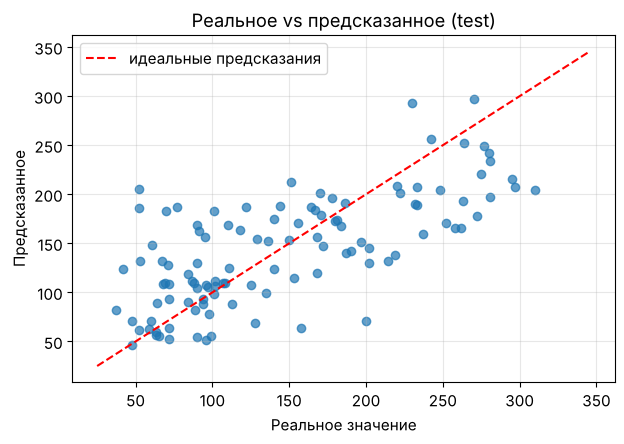

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.7)
lims = [y.min(), y.max()]
plt.plot(lims, lims, "r--", label="идеальные предсказания")
plt.xlabel("Реальное значение"); plt.ylabel("Предсказанное"); plt.legend()
plt.title("Реальное vs предсказанное (test)")
plt.show()

---
## 7. Коэффициенты и масштаб признаков

### Что говорят коэффициенты

`coef_` — это «вес» каждого признака. Знак показывает направление влияния, величина — силу. Формально: **если признак $j$ вырос на 1, а остальные не менялись, то предсказание изменится на $w_j$.**

In [ ]:
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print("свободный член b =", round(model.intercept_, 2))
coefs

свободный член b = 151.67

s1    -918.5029
sex   -241.9909
s6      26.3246
age     47.7497
s3     116.9502
s4     269.4923
bp     381.5629
s2     508.2578
bmi    531.9711
s5     695.8081
dtype: float64

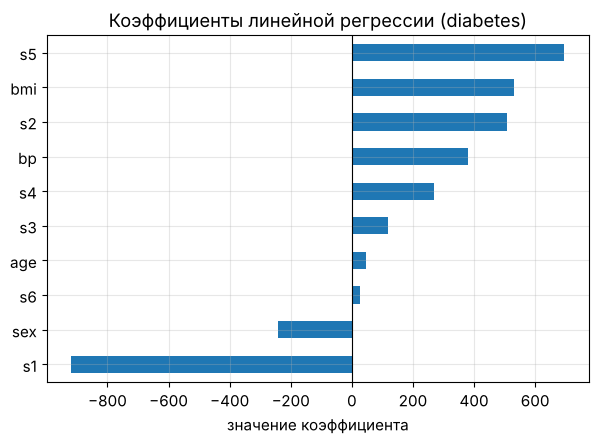

In [ ]:
coefs.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Коэффициенты линейной регрессии (diabetes)")
plt.xlabel("значение коэффициента")
plt.show()

Положительные веса у `bmi` (индекс массы тела) и `s5` — при их росте прогноз прогрессирования болезни растёт. Но осторожно с выводами про `s1`, `s2`: у них большие веса **с противоположными знаками**. Это симптом **мультиколлинеарности**, о которой — в разделе 9.

### Проблема: коэффициенты зависят от масштаба

Если измерять рост в **сантиметрах**, его коэффициент будет в 100 раз меньше, чем если измерять в **метрах**. Поэтому сравнивать веса признаков разной размерности «в лоб» нельзя: большой вес не обязательно означает большую важность.

Решение: привести все признаки к одному масштабу. Стандартный способ — **стандартизация** (`StandardScaler`): из каждого признака вычитаем среднее и делим на стандартное отклонение:

$$x' = \frac{x - \mu}{\sigma}$$

Тогда у всех признаков среднее 0 и стандартное отклонение 1, и вес $w_j$ означает «на сколько изменится прогноз при росте признака на одно стандартное отклонение». Так веса сравнимы.

### Главное правило: никакой утечки данных

Среднее $\mu$ и $\sigma$ нужно считать **только по train** и потом применять и к train, и к test. Если посчитать по всем данным, то информация о тесте «просочится» в обучение (**data leakage**), и оценка качества будет слишком оптимистичной.

Чтобы не ошибиться, используют **Pipeline**: цепочку шагов, которая сама правильно делает `fit` на train и `transform` на test. `make_pipeline` собирает её:

In [ ]:
pipe = make_pipeline(StandardScaler(), LinearRegression())
pipe.fit(X_train, y_train)          # scaler.fit_transform(train) → LinearRegression.fit
pipe_pred = pipe.predict(X_test)    # scaler.transform(test) → LinearRegression.predict

print("R² с масштабированием:   ", round(r2_score(y_test, pipe_pred), 4))
print("R² без масштабирования:  ", round(r2_score(y_test, y_pred), 4))
print("Предсказания одинаковы:  ", np.allclose(pipe_pred, y_pred))

lin = pipe[-1]    # доступ к шагу pipeline: последний шаг (или pipe["linearregression"])
pd.DataFrame({"до масштабирования": model.coef_, "после": lin.coef_}, index=X.columns)

R² с масштабированием:    0.4849
R² без масштабирования:   0.4849
Предсказания одинаковы:   True

,до масштабирования,после
age,47.7497,2.2151
sex,-241.9909,-11.5145
bmi,531.9711,25.0770
bp,381.5629,18.2493
s1,-918.5029,-44.1446
s2,508.2578,24.5139
s3,116.9502,5.4976
s4,269.4923,13.0068
s5,695.8081,33.3798
s6,26.3246,1.2480


Важное наблюдение: **качество обычной линейной регрессии от масштаба не зависит** (предсказания совпали), меняются только коэффициенты (в новой шкале они сравнимы между собой). Но для моделей с регуляризацией (раздел 9), градиентного спуска и многих других алгоритмов масштабирование критично. Поэтому правило «масштабируй признаки в Pipeline» — хорошая привычка.

---
## 8. Переобучение и недообучение

Линейная модель называется линейной по **параметрам**, а не по признакам. Если добавить в данные $x^2, x^3, \dots$, то «линейная» регрессия сможет рисовать кривые:

$$\hat y = w_0 + w_1 x + w_2 x^2 + \dots + w_d x^d$$

Это **полиномиальная регрессия**; степень $d$ задаёт сложность модели. В sklearn признаки $x^2, x^3, \dots$ создаёт `PolynomialFeatures`. Посмотрим, что делает рост сложности. Данные: настоящая закономерность $y = \sin(2\pi x)$ + шум, всего 20 обучающих точек и шум со стандартным отклонением 0.3.

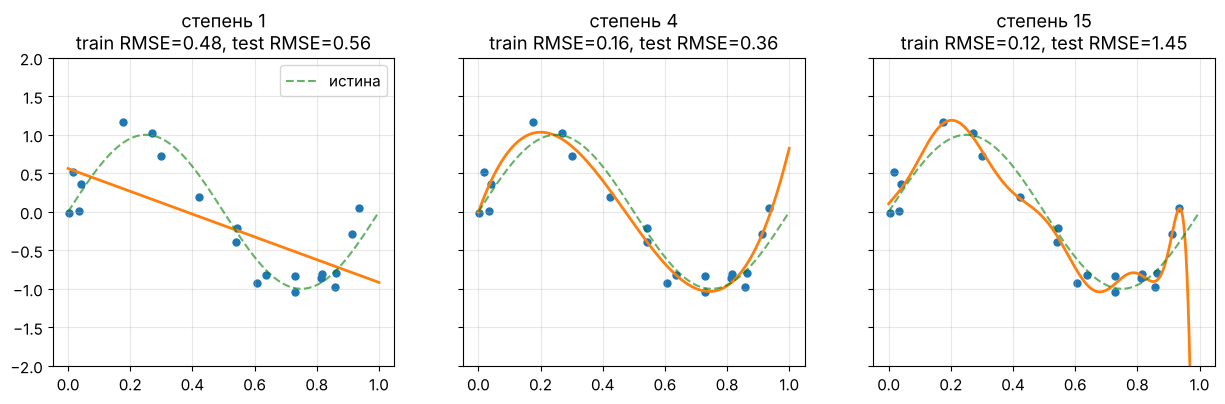

In [ ]:
rng = np.random.default_rng(0)

def make_data(n):
    x = np.sort(rng.uniform(0, 1, n))
    return x.reshape(-1, 1), np.sin(2 * np.pi * x) + rng.normal(0, 0.3, n)

Xs_train, ys_train = make_data(20)
Xs_test,  ys_test  = make_data(200)
x_line = np.linspace(0, 1, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, degree in zip(axes, [1, 4, 15]):
    poly_model = make_pipeline(PolynomialFeatures(degree, include_bias=False),
                               StandardScaler(), LinearRegression())
    poly_model.fit(Xs_train, ys_train)
    tr = root_mean_squared_error(ys_train, poly_model.predict(Xs_train))
    te = root_mean_squared_error(ys_test,  poly_model.predict(Xs_test))
    ax.scatter(Xs_train, ys_train, s=25)
    ax.plot(x_line, poly_model.predict(x_line), color="C1", linewidth=2)
    ax.plot(x_line, np.sin(2 * np.pi * x_line), "g--", alpha=0.6, label="истина")
    ax.set_title(f"степень {degree}\ntrain RMSE={tr:.2f}, test RMSE={te:.2f}")
    ax.set_ylim(-2, 2)
axes[0].legend()
plt.show()

Три картинки — три типичные ситуации:

- **Степень 1 — недообучение (underfitting).** Модель слишком простая и не может уловить синусоиду. Ошибка высока и на train, и на test.
- **Степень 4 — золотая середина.** Кривая повторяет форму закономерности, а test-ошибка близка к минимально возможной (шум в данных 0.3 никакая модель не уберёт: он случаен).
- **Степень 15 — переобучение (overfitting).** Модель настолько гибкая, что подстроилась под шум конкретных 20 точек. На train ошибка самая маленькая, а на test она в разы больше (кривая беснуется между точками и на краях).

**Признак переобучения: качество на train сильно лучше, чем на test.** Построим кривую зависимости ошибок от сложности:

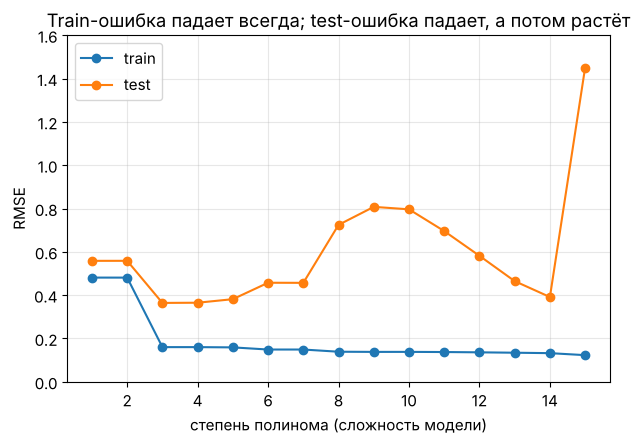

In [ ]:
degrees = range(1, 16)
train_err, test_err = [], []
for d in degrees:
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    m.fit(Xs_train, ys_train)
    train_err.append(root_mean_squared_error(ys_train, m.predict(Xs_train)))
    test_err.append(root_mean_squared_error(ys_test,  m.predict(Xs_test)))

plt.plot(degrees, train_err, "o-", label="train")
plt.plot(degrees, test_err, "o-", label="test")
plt.ylim(0, 1.6)
plt.xlabel("степень полинома (сложность модели)"); plt.ylabel("RMSE"); plt.legend()
plt.title("Train-ошибка падает всегда; test-ошибка падает, а потом растёт")
plt.show()

Это одна из самых важных картинок в машинном обучении. **Ошибка на train падает с ростом сложности всегда, и по ней нельзя выбирать модель.** Ошибка на test имеет минимум, и нужная сложность находится там. Дальше — переобучение.

Что делать с переобучением: больше данных, проще модель, **регуляризация**. Последнее — следующий раздел.

---
## 9. Регуляризация: Ridge и Lasso

Заметь, что при переобучении у модели обычно **огромные коэффициенты**: кривая резко «виляет», чтобы пройти через каждую точку. Идея регуляризации: **штрафовать модель за большие веса**, добавив штраф в функцию потерь.

**Ridge (гребневая, L2-регуляризация):**
$$\text{Loss} = \text{MSE} + \alpha \sum_{j} w_j^2$$

**Lasso (L1-регуляризация):**
$$\text{Loss} = \text{MSE} + \alpha \sum_{j} \lvert w_j\rvert$$

(свободный член $b$ не штрафуется). Параметр $\alpha \ge 0$ — **сила регуляризации**: при $\alpha = 0$ получаем обычную регрессию, чем больше $\alpha$, тем сильнее веса прижимаются к нулю и тем проще (жёстче) модель.

| | Ridge | Lasso |
|---|---|---|
| Штраф | сумма квадратов весов | сумма модулей весов |
| Что делает с весами | уменьшает все, но **не обнуляет** | часть весов **обнуляет полностью** |
| Когда полезна | признаки коррелируют, нужна стабильность | нужен **отбор признаков** (лишние отсеиваются) |

Из-за штрафа регуляризованные модели **чувствительны к масштабу признаков** (штраф одинаков для всех весов, а масштабы разные), поэтому масштабируй данные: `make_pipeline(StandardScaler(), Ridge(alpha=...))`.

### Лечим переобучение из раздела 8

Возьмём ту же полиномиальную модель степени 15 и добавим Ridge:

In [ ]:
def poly_rmse(alpha, degree=15):
    reg = LinearRegression() if alpha == 0 else Ridge(alpha=alpha)
    m = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), reg)
    m.fit(Xs_train, ys_train)
    return (root_mean_squared_error(ys_train, m.predict(Xs_train)),
            root_mean_squared_error(ys_test,  m.predict(Xs_test)))

rows = []
for a in [0, 1e-6, 1e-4, 1e-2, 1e-1, 1, 10]:
    tr, te = poly_rmse(a)
    rows.append({"alpha": a, "train RMSE": tr, "test RMSE": te})
pd.DataFrame(rows).set_index("alpha")

,train RMSE,test RMSE
alpha,,
0.0000e+00,0.1228,1.4511
1.0000e-06,0.1459,0.7719
1.0000e-04,0.1479,0.6584
1.0000e-02,0.1780,0.4164
1.0000e-01,0.2473,0.4082
1.0000e+00,0.3276,0.5759
1.0000e+01,0.3882,0.5194


При $\alpha = 0$ (обычная регрессия) test-ошибка огромная (около 1.45). С умеренным $\alpha$ (порядка 0.01–0.1) она падает в 3–4 раза: модель с 15 степенями свободы «одёрнута» штрафом и перестала подгонять шум. Обрати внимание: **train-ошибка при этом растёт**, и это нормально, ведь мы сознательно запрещаем модели подгоняться под обучающие точки. При слишком большом $\alpha$ модель становится слишком жёсткой, и test-ошибка снова становится выше минимума (недообучение). Значит, **$\alpha$ нужно подбирать**, и об этом ниже.

### Как коэффициенты меняются с ростом $\alpha$

На данных diabetes (с масштабированием) нарисуем **пути коэффициентов**: как каждый вес зависит от $\alpha$.

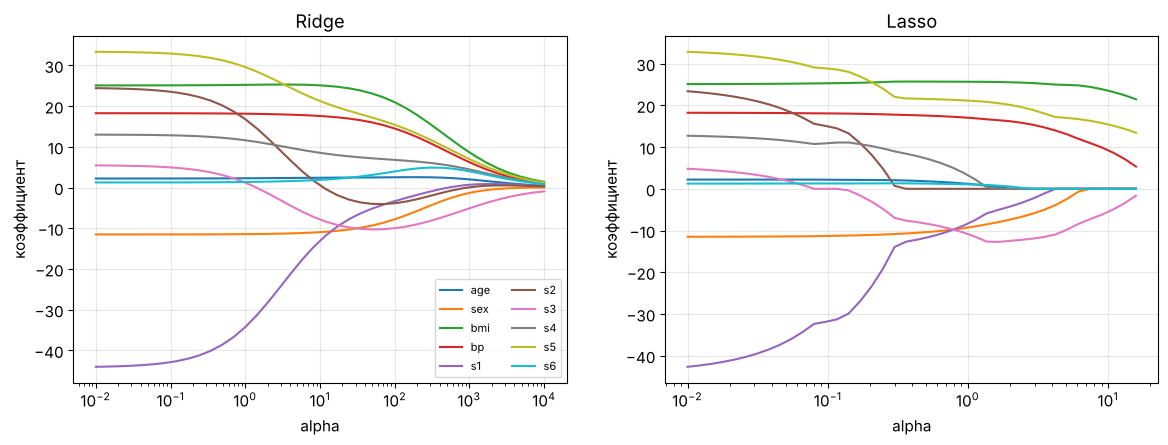

In [ ]:
alphas_ridge = np.logspace(-2, 4, 40)
alphas_lasso = np.logspace(-2, 1.2, 40)
Xs_sc = StandardScaler().fit_transform(X_train)   # для демонстрации масштабируем train целиком

ridge_paths = np.array([Ridge(alpha=a).fit(Xs_sc, y_train).coef_ for a in alphas_ridge])
lasso_paths = np.array([Lasso(alpha=a, max_iter=10000).fit(Xs_sc, y_train).coef_ for a in alphas_lasso])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, paths, al, name in [(axes[0], ridge_paths, alphas_ridge, "Ridge"),
                            (axes[1], lasso_paths, alphas_lasso, "Lasso")]:
    for j, col in enumerate(X.columns):
        ax.plot(al, paths[:, j], label=col)
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.set_ylabel("коэффициент"); ax.set_title(name)
axes[0].legend(ncol=2, fontsize=8)
plt.show()

Разница видна: у **Ridge** все веса плавно сжимаются к нулю, но никогда не равны нулю в точности. У **Lasso** при росте $\alpha$ веса один за другим **становятся ровно нулём**, то есть признаки отключаются (отбор признаков). Лишние признаки уходят первыми, самые полезные (`bmi`, `s5`) держатся дольше всех.

### Мультиколлинеарность: почему `s1` и `s2` вели себя странно

Если два признака почти дублируют друг друга, то обычной регрессии «всё равно», как делить вес между ними: можно дать +1000 одному и −1000 другому, предсказания почти не изменятся. Коэффициенты получаются **неустойчивыми и неинтерпретируемыми**. Проверим корреляцию `s1` и `s2`:

In [ ]:
print("корреляция s1 и s2:", round(X["s1"].corr(X["s2"]), 3))

ols = LinearRegression().fit(X_train, y_train)
rdg = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(X_train, y_train)
# чтобы сравнить Ridge с OLS в одной шкале, пересчитаем веса Ridge обратно в шкалу исходных данных
rdg_coef_raw = rdg[-1].coef_ / StandardScaler().fit(X_train).scale_

pd.DataFrame({"OLS": ols.coef_, "Ridge(alpha=10), в исх. шкале": rdg_coef_raw}, index=X.columns).loc[["s1", "s2", "s3", "s4", "bmi"]]

корреляция s1 и s2: 0.897

,OLS,"Ridge(alpha=10), в исх. шкале"
s1,-918.5029,-271.6943
s2,508.2578,11.3360
s3,116.9502,-166.9746
s4,269.4923,176.6376
bmi,531.9711,532.2429


У обычной регрессии `s1` и `s2` — огромные веса разных знаков (−918 и +508), у Ridge они заметно скромнее (особенно `s2`). Заметь также, что `bmi` почти не изменился: он ни с кем не коррелирует так сильно, и штраф ему не мешает. **Ridge — лекарство от мультиколлинеарности.**

### Как выбрать $\alpha$: кросс-валидация

Подбирать $\alpha$ по тесту нельзя: тогда тест перестаёт быть честным. Нужен другой механизм: **кросс-валидация** (cross-validation, CV). Идея на примере $k=5$:

```
Весь train разбиваем на 5 частей (folds):
 запуск 1:  [ТЕСТ] [train] [train] [train] [train]
 запуск 2:  [train] [ТЕСТ] [train] [train] [train]
 запуск 3:  [train] [train] [ТЕСТ] [train] [train]
 запуск 4:  [train] [train] [train] [ТЕСТ] [train]
 запуск 5:  [train] [train] [train] [train] [ТЕСТ]
```

Каждый раз учимся на 4 частях и проверяем на оставшейся. Получаем 5 оценок и усредняем: так оценка надёжнее, чем по одному разбиению. Настоящий `test` при этом остаётся нетронутым и используется один раз в самом конце.

В sklearn: `cross_val_score(модель, X, y, cv=5, scoring=...)`. Для регрессии метрики-«ошибки» в `scoring` берутся с минусом (`neg_root_mean_squared_error`), потому что sklearn всегда **максимизирует** оценку.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for alpha in [0.01, 1, 10, 100, 1000]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    rmse_cv = -cross_val_score(m, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    print(f"alpha={alpha:>7}:  CV RMSE = {rmse_cv.mean():.2f}  (±{rmse_cv.std():.2f})")

alpha=   0.01:  CV RMSE = 56.12  (±3.13)
alpha=      1:  CV RMSE = 56.07  (±3.20)
alpha=     10:  CV RMSE = 56.11  (±3.30)
alpha=    100:  CV RMSE = 56.83  (±3.09)
alpha=   1000:  CV RMSE = 65.36  (±3.06)

Для Ridge и Lasso есть готовые версии с **встроенным подбором $\alpha$ по кросс-валидации**: `RidgeCV` и `LassoCV`. Они перебирают сетку $\alpha$ сами:

In [ ]:
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 50), cv=5)).fit(X_train, y_train)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=20000)).fit(X_train, y_train)

print("лучший alpha у Ridge:", round(ridge_cv[-1].alpha_, 2))
print("лучший alpha у Lasso:", round(lasso_cv[-1].alpha_, 3))

final = pd.DataFrame({
    "R² (test)": [r2_score(y_test, m.predict(X_test)) for m in [pipe, ridge_cv, lasso_cv]],
    "RMSE (test)": [root_mean_squared_error(y_test, m.predict(X_test)) for m in [pipe, ridge_cv, lasso_cv]],
}, index=["LinearRegression", "RidgeCV", "LassoCV"])
final

лучший alpha у Ridge: 29.47
лучший alpha у Lasso: 0.106

,R² (test),RMSE (test)
LinearRegression,0.4849,53.3696
RidgeCV,0.4907,53.0710
LassoCV,0.4867,53.2768


In [ ]:
lasso_coef = pd.Series(lasso_cv[-1].coef_, index=X.columns)
print("Lasso обнулил признаки:", list(lasso_coef[lasso_coef == 0].index))
lasso_coef.round(2)

Lasso обнулил признаки: ['s3']

age     2.18
sex   -11.28
bmi    25.30
bp     18.07
s1    -31.59
s2     14.78
s3     -0.00
s4     10.99
s5     28.73
s6      1.28
dtype: float64

На этом датасете выигрыш регуляризации по метрике небольшой (признаков мало, данных достаточно), но ты увидел весь механизм. Регуляризация даёт максимум пользы, когда **признаков много, а данных мало**, и это типичная ситуация на практике.

---
## 10. Подводные камни линейной регрессии

У линейной регрессии есть предположения. Знать их нужно, чтобы вовремя замечать проблемы.

1. **Связь действительно (примерно) линейная.** Если нет, модель систематически ошибается (см. недообучение; лечится добавлением полиномиальных признаков или другой моделью).
2. **Выбросы.** Квадрат в MSE сильно штрафует большие ошибки, поэтому одна «странная» точка может утащить за собой всю прямую.
3. **Мультиколлинеарность** (раздел 9): дублирующие друг друга признаки → неустойчивые веса.
4. **Масштаб** важен для регуляризации и интерпретации весов (раздел 7).
5. **Экстраполяция.** Линия продолжается бесконечно: для площади 1000 м² модель «спокойно» выдаст цену, но верить ей не стоит.

### Выбросы: эксперимент

Добавим в данные про квартиры одну аномальную точку (площадь 40 м², цена 15 млн, возможно, опечатка) и посмотрим, как сдвинется прямая:

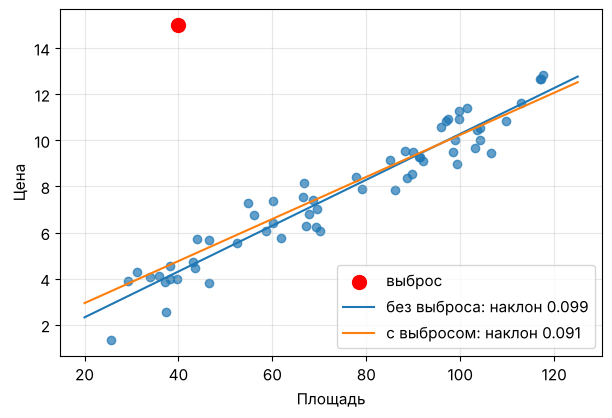

In [ ]:
X_out = np.vstack([df[["area"]].values, [[40]]])
y_out = np.append(df["price"].values, 15)

clean = LinearRegression().fit(df[["area"]], df["price"])
dirty = LinearRegression().fit(X_out, y_out)

plt.scatter(df["area"], df["price"], alpha=0.7)
plt.scatter([40], [15], color="red", s=100, label="выброс", zorder=3)
xg = np.linspace(20, 125, 2).reshape(-1, 1)
plt.plot(xg, clean.predict(pd.DataFrame(xg, columns=["area"])), label=f"без выброса: наклон {clean.coef_[0]:.3f}")
plt.plot(xg, dirty.predict(xg), label=f"с выбросом: наклон {dirty.coef_[0]:.3f}")
plt.legend(); plt.xlabel("Площадь"); plt.ylabel("Цена")
plt.show()

Всего одна точка из 61 изменила наклон и сдвинула всю прямую вверх (особенно заметно слева). Будь выброс ещё экстремальнее, эффект был бы сильнее. Что делать: проверить данные (это может быть ошибка), удалить или исправить выброс, или взять **робастную** модель (в sklearn — `HuberRegressor`, `RANSACRegressor`, `TheilSenRegressor`), которая менее чувствительна к выбросам.

### Диагностика: график остатков

После обучения полезно посмотреть на остатки $e_i = y_i - \hat y_i$. У хорошей модели они разбросаны **случайно вокруг нуля**, без видимого узора. Если на графике «остатки против предсказаний» видна дуга или воронка, то модель упускает закономерность (нелинейность) или дисперсия ошибок меняется.

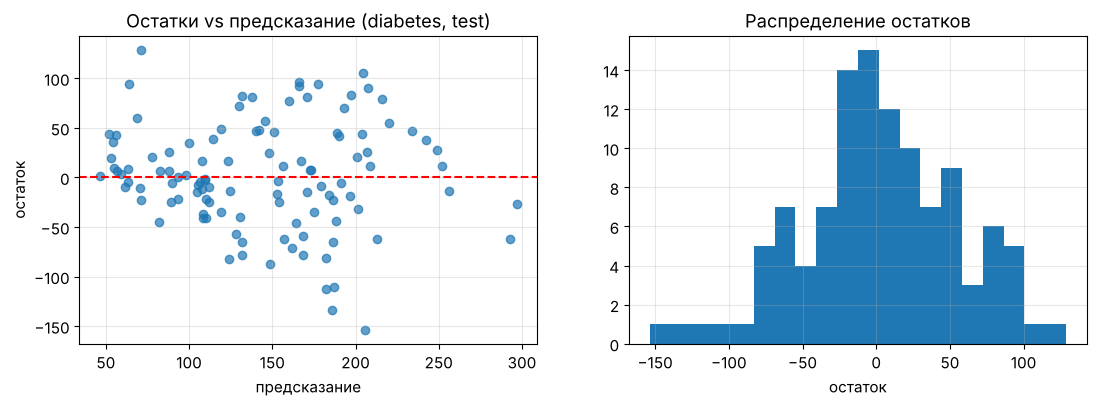

In [ ]:
resid = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(y_pred, resid, alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("предсказание"); axes[0].set_ylabel("остаток"); axes[0].set_title("Остатки vs предсказание (diabetes, test)")
axes[1].hist(resid, bins=20)
axes[1].set_xlabel("остаток"); axes[1].set_title("Распределение остатков")
plt.show()

---
## 11. Шпаргалка

**Рецепт на каждую задачу регрессии:**

```python
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import root_mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 50)))
model.fit(X_train, y_train)

pred = model.predict(X_test)
print(root_mean_squared_error(y_test, pred), r2_score(y_test, pred))
```

| Что нужно | Как |
|---|---|
| Обычная линейная регрессия | `LinearRegression()` |
| Борьба с переобучением, коррелирующие признаки | `Ridge(alpha)`, `RidgeCV` |
| Отбор признаков | `Lasso(alpha)`, `LassoCV` |
| Кривые, нелинейность | `PolynomialFeatures(degree)` в Pipeline |
| Разделить данные | `train_test_split` |
| Устойчивая оценка качества | `cross_val_score(..., cv=5)` |
| Метрики | `mean_absolute_error`, `root_mean_squared_error`, `r2_score` |
| Масштабирование без утечки | `make_pipeline(StandardScaler(), ...)` |
| Точка отсчёта | `DummyRegressor(strategy="mean")` |
| Параметры после обучения | `.coef_`, `.intercept_` |

**Главное, что нужно запомнить:**
1. Модель = формула + параметры; обучение = минимизация функции потерь.
2. Качество измеряем только на данных, которых модель не видела; сравниваем с baseline.
3. Ошибка на train сильно меньше, чем на test, значит переобучение: упрощай модель или добавляй регуляризацию.
4. `fit` для масштабирования и любых преобразований только на train: используй Pipeline.

---
# Упражнения

Решай в ячейках ниже. **Решения в самом конце ноутбука** — подглядывай только после своей попытки. Если застрял, вернись к соответствующему разделу.

### Упражнение 1. Метрики вручную (раздел 6)

Даны `y_true = [10, 12, 15, 20, 23]` и `y_pred = [11, 12, 14, 22, 21]`. Посчитай MAE, MSE, RMSE и $R^2$ **через numpy, без sklearn.metrics**, затем сверь результат со sklearn. Должно получиться как в ручном расчёте в начале раздела 6.

In [ ]:
# Ваш код здесь

### Упражнение 2. Стаж и зарплата (разделы 2–5)

Данные сгенерированы ниже: стаж в годах и зарплата в тыс. ₽. Задание:
1. Раздели данные на train/test (30% на тест, `random_state=1`).
2. Обучи `LinearRegression`, выведи вес и свободный член.
3. Скажи словами, что означает вес.
4. Предскажи зарплату при стаже 7 лет.
5. Посчитай $R^2$ на тесте.

In [ ]:
rng2 = np.random.default_rng(0)
exp_years = rng2.uniform(0, 15, 40)
salary = 40 + 6 * exp_years + rng2.normal(0, 8, 40)
salary_df = pd.DataFrame({"experience": exp_years, "salary": salary})

# Ваш код здесь

### Упражнение 3. Один признак против всех (разделы 5–7)

На данных diabetes (используй `X_train`, `X_test`, `y_train`, `y_test` из раздела 5):
1. Обучи модель **только на признаке `bmi`** и посчитай $R^2$ на тесте.
2. Сравни с моделью на всех признаках. Насколько выросло качество?
3. Обучи `Pipeline` со `StandardScaler` на всех признаках и выведи **три признака с наибольшим по модулю** коэффициентом.

In [ ]:
# Ваш код здесь

### Упражнение 4. Нормальное уравнение (раздел 3.3)

Реализуй $w = (X^\top X)^{-1} X^\top y$ на numpy для данных diabetes (train). Подсказка: чтобы учесть свободный член, добавь к $X$ столбец из единиц (`np.c_[np.ones(len(X_train)), X_train]`). Вместо явного обращения матрицы используй `np.linalg.solve(A, b)`: решает систему $A w = b$ точнее и быстрее. Сравни с `LinearRegression` (`np.allclose`).

In [ ]:
# Ваш код здесь

### Упражнение 5. Выбор степени полинома кросс-валидацией (разделы 8–9)

Используя `Xs_train`, `ys_train` (синусоида из раздела 8), для степеней от 1 до 12 посчитай CV-RMSE (`cv=5`, `KFold` с `shuffle=True`), выбери лучшую степень и проверь её на `Xs_test`. Совпала ли она с твоим впечатлением от графиков в разделе 8?

In [ ]:
# Ваш код здесь

### Упражнение 6. Lasso и отбор признаков (раздел 9)

На данных diabetes в Pipeline со `StandardScaler`: для $\alpha \in \{0.01, 0.1, 1, 3, 10\}$ обучи Lasso на train и выведи, **сколько коэффициентов стало нулевыми** и каков RMSE на тесте. Затем найди «оптимальное» $\alpha$ через `LassoCV` и скажи, какие признаки оно оставило.

In [ ]:
# Ваш код здесь

---
# Решения упражнений

Лучше сначала решить самому. Если уже попробовал, то сверяйся.

### Решение 1

In [ ]:
y_true = np.array([10, 12, 15, 20, 23])
y_pred_ex = np.array([11, 12, 14, 22, 21])

e = y_true - y_pred_ex
mae_ = np.mean(np.abs(e))
mse_ = np.mean(e ** 2)
rmse_ = np.sqrt(mse_)
r2_ = 1 - np.sum(e ** 2) / np.sum((y_true - y_true.mean()) ** 2)
print(f"вручную: MAE={mae_:.3f}, MSE={mse_:.3f}, RMSE={rmse_:.3f}, R²={r2_:.4f}")
print(f"sklearn: MAE={mean_absolute_error(y_true, y_pred_ex):.3f}, MSE={mean_squared_error(y_true, y_pred_ex):.3f}, "
      f"RMSE={root_mean_squared_error(y_true, y_pred_ex):.3f}, R²={r2_score(y_true, y_pred_ex):.4f}")

вручную: MAE=1.200, MSE=2.000, RMSE=1.414, R²=0.9153
sklearn: MAE=1.200, MSE=2.000, RMSE=1.414, R²=0.9153

### Решение 2

In [ ]:
Xe = salary_df[["experience"]]
ye = salary_df["salary"]
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(Xe, ye, test_size=0.3, random_state=1)

m2 = LinearRegression().fit(Xe_tr, ye_tr)
print(f"вес = {m2.coef_[0]:.2f}, свободный член = {m2.intercept_:.2f}")
print("Смысл веса: каждый дополнительный год стажа в среднем добавляет ≈ столько тыс. ₽ к зарплате.")
print("Зарплата при стаже 7 лет:", round(m2.predict(pd.DataFrame({"experience": [7]}))[0], 1), "тыс. ₽")
print("R² на тесте:", round(m2.score(Xe_te, ye_te), 3))

вес = 6.38, свободный член = 38.15
Смысл веса: каждый дополнительный год стажа в среднем добавляет ≈ столько тыс. ₽ к зарплате.
Зарплата при стаже 7 лет: 82.8 тыс. ₽
R² на тесте: 0.889

(Данные генерировались как $40 + 6 \cdot \text{стаж} + \text{шум}$, поэтому вес должен получиться около 6, а свободный член около 40, с небольшим отклонением из-за шума и малого объёма выборки.)

### Решение 3

In [ ]:
# 1) только bmi
m_bmi = LinearRegression().fit(X_train[["bmi"]], y_train)
r2_bmi = m_bmi.score(X_test[["bmi"]], y_test)

# 2) все признаки
r2_all = LinearRegression().fit(X_train, y_train).score(X_test, y_test)
print(f"R² только bmi: {r2_bmi:.3f} | R² на всех признаках: {r2_all:.3f}")

# 3) топ-3 по модулю коэффициента при стандартизации
p3 = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
w3 = pd.Series(p3[-1].coef_, index=X.columns)
print("\nТоп-3 по |коэффициенту|:")
print(w3.reindex(w3.abs().sort_values(ascending=False).index).head(3).round(2))

R² только bmi: 0.317 | R² на всех признаках: 0.485

Топ-3 по |коэффициенту|:
s1    -44.14
s5     33.38
bmi    25.08
dtype: float64

### Решение 4

In [ ]:
Xb = np.c_[np.ones(len(X_train)), X_train.values]     # столбец единиц для b + признаки
w_ne = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_train.values)   # (XᵀX) w = Xᵀy

b_ne, coef_ne = w_ne[0], w_ne[1:]
lr_ref = LinearRegression().fit(X_train, y_train)
print("b совпал:      ", np.isclose(b_ne, lr_ref.intercept_))
print("веса совпали:  ", np.allclose(coef_ne, lr_ref.coef_))

b совпал:       True
веса совпали:   True

### Решение 5

In [ ]:
kf5 = KFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = {}
for d in range(1, 13):
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    cv_scores[d] = -cross_val_score(m, Xs_train, ys_train, cv=kf5, scoring="neg_root_mean_squared_error").mean()

cv_series = pd.Series(cv_scores)
best_d = int(cv_series.idxmin())
print(cv_series.round(3).to_string())
print("\nЛучшая степень по CV:", best_d)

best_m = make_pipeline(PolynomialFeatures(best_d, include_bias=False), StandardScaler(), LinearRegression()).fit(Xs_train, ys_train)
print("test RMSE выбранной модели:", round(root_mean_squared_error(ys_test, best_m.predict(Xs_test)), 3))

1     0.546
2     0.629
3     0.191
4     0.243
5     0.281
6     0.300
7     0.575
8     0.422
9     0.325
10    0.371
11    1.552
12    1.809

Лучшая степень по CV: 3
test RMSE выбранной модели: 0.364

CV выбирает небольшую степень (3–4), то есть ту же «золотую середину», что и на графиках раздела 8, **и делает это, ни разу не заглянув в тест**.

### Решение 6

In [ ]:
for a in [0.01, 0.1, 1, 3, 10]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=20000)).fit(X_train, y_train)
    n_zero = int(np.sum(m[-1].coef_ == 0))
    rm = root_mean_squared_error(y_test, m.predict(X_test))
    print(f"alpha={a:>5}: обнулено {n_zero} из 10, test RMSE = {rm:.2f}")

lcv = make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=20000)).fit(X_train, y_train)
kept = X.columns[lcv[-1].coef_ != 0]
print(f"\nLassoCV: alpha = {lcv[-1].alpha_:.3f}, оставил признаки: {list(kept)}")

alpha= 0.01: обнулено 0 из 10, test RMSE = 53.36
alpha=  0.1: обнулено 1 из 10, test RMSE = 53.28
alpha=    1: обнулено 1 из 10, test RMSE = 52.77
alpha=    3: обнулено 4 из 10, test RMSE = 52.51
alpha=   10: обнулено 6 из 10, test RMSE = 53.71

LassoCV: alpha = 0.106, оставил признаки: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']

С ростом $\alpha$ всё больше коэффициентов становится нулевыми, а ошибка сначала почти не меняется (мы убираем лишние признаки бесплатно, иногда она даже слегка улучшается), потом растёт (убираем полезные). `LassoCV` выбирает компромисс автоматически.

---

**Что дальше:** ноутбук 2 — логистическая регрессия. Там всё, что ты выучил здесь (признаки, веса, функция потерь, градиентный спуск, train/test, регуляризация, Pipeline), пригодится в почти неизменном виде. Меняется только то, что мы предсказываем: не число, а **вероятность класса**.